# Exploratório 01 — Interpolação e KNN diários

Reproduzir a tentativa anterior para comparação. Não é o procedimento recomendado para os 208 dias sem estação.

**Entradas:** CSVs originais; filtro textual histórico 07-07FX.

**Saídas:** data/interim/exploratorio/; reports/exploratorio/imputacao/; figura.

Execute de cima para baixo com o kernel `.venv`. O notebook encontra a raiz do projeto automaticamente.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "energia_transfer").is_dir())
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))
from energia_transfer.caminhos import CaminhosProjeto
CAMINHOS = CaminhosProjeto(RAIZ)
CAMINHOS.preparar_saidas()

def exibir_tabela(tabela, casas=3):
    copia = tabela.copy()
    numericas = copia.select_dtypes(include="number").columns
    copia[numericas] = copia[numericas].round(casas)
    display(copia)

## Status da experiência

Esta tentativa conserva o filtro antigo para reproduzir a análise original. A recuperação por identidade e a seleção recomendada estão nos notebooks principais. O preenchimento diário não valida o semestre sem meteorologia; colunas sem medição permanecem ausentes.

In [2]:
from energia_transfer.exploratorios import executar_imputacao_diaria
resultado_knn = executar_imputacao_diaria(CAMINHOS)
exibir_tabela(resultado_knn["relatorio"])
exibir_tabela(resultado_knn["escolhas"])
exibir_tabela(resultado_knn["validacao"].head(15))

,dias_observados,faltantes_antes_pct,maior_lacuna_dias,dias_interpolados,dias_knn,faltantes_depois_pct,estimados_pct,dias_estimados_alem_validacao
Active_Energy_Delivered_Received,338,6.887,22,24,1,0.0,6.887,0
Current_Phase_Average,338,6.887,22,2,23,0.0,6.887,0
Active_Power,338,6.887,22,2,23,0.0,6.887,0
Wind_Speed,140,61.433,208,15,208,0.0,61.433,208
Weather_Temperature_Celsius,140,61.433,208,6,217,0.0,61.433,208
Weather_Relative_Humidity,0,100.000,363,0,0,100.0,0.000,0
Global_Horizontal_Radiation,140,61.433,208,15,208,0.0,61.433,208
Diffuse_Horizontal_Radiation,0,100.000,363,0,0,100.0,0.000,0
Wind_Direction,140,61.433,208,15,208,0.0,61.433,208
Weather_Daily_Rainfall,140,61.433,208,15,208,0.0,61.433,208


,coluna,knn_escolhido,melhor_metodo_validacao,NRMSE_validacao_knn,NRMSE_validacao_linear,limite_linear_aplicado_dias,maior_bloco_validado_dias,dias_lineares,dias_knn
0,Active_Energy_Delivered_Received,knn_7,linear,0.040,0.004,30,30,24,1
1,Current_Phase_Average,knn_7,knn_7,0.883,0.920,2,30,2,23
2,Active_Power,knn_7,knn_7,0.934,1.025,2,30,2,23
3,Wind_Speed,knn_3,linear,0.714,0.665,30,30,15,208
4,Weather_Temperature_Celsius,knn_7,knn_7,0.721,0.802,2,30,6,217
5,Global_Horizontal_Radiation,knn_5,linear,0.036,0.035,30,30,15,208
6,Wind_Direction,knn_3,linear,0.000,0.000,30,30,15,208
7,Weather_Daily_Rainfall,knn_3,linear,0.970,0.884,30,30,15,208
8,Radiation_Global_Tilted,knn_7,knn_7,0.354,0.397,2,30,6,217


,coluna,metodo,bloco_dias,MAE,RMSE,NRMSE,pontos,repeticoes
0,Active_Energy_Delivered_Received,knn_3,1,2439.631,2439.631,0.004,4,4
1,Active_Energy_Delivered_Received,knn_3,7,12330.892,13344.095,0.024,28,4
2,Active_Energy_Delivered_Received,knn_3,30,48116.336,53837.186,0.095,120,4
3,Active_Energy_Delivered_Received,knn_5,1,1744.431,1744.431,0.003,4,4
4,Active_Energy_Delivered_Received,knn_5,7,11583.046,12563.105,0.022,28,4
5,Active_Energy_Delivered_Received,knn_5,30,49555.398,54860.698,0.097,120,4
6,Active_Energy_Delivered_Received,knn_7,1,1412.433,1412.433,0.003,4,4
7,Active_Energy_Delivered_Received,knn_7,7,10254.873,11243.819,0.020,28,4
8,Active_Energy_Delivered_Received,knn_7,30,50667.866,55714.338,0.098,120,4
9,Active_Energy_Delivered_Received,linear,1,633.870,633.870,0.001,4,4


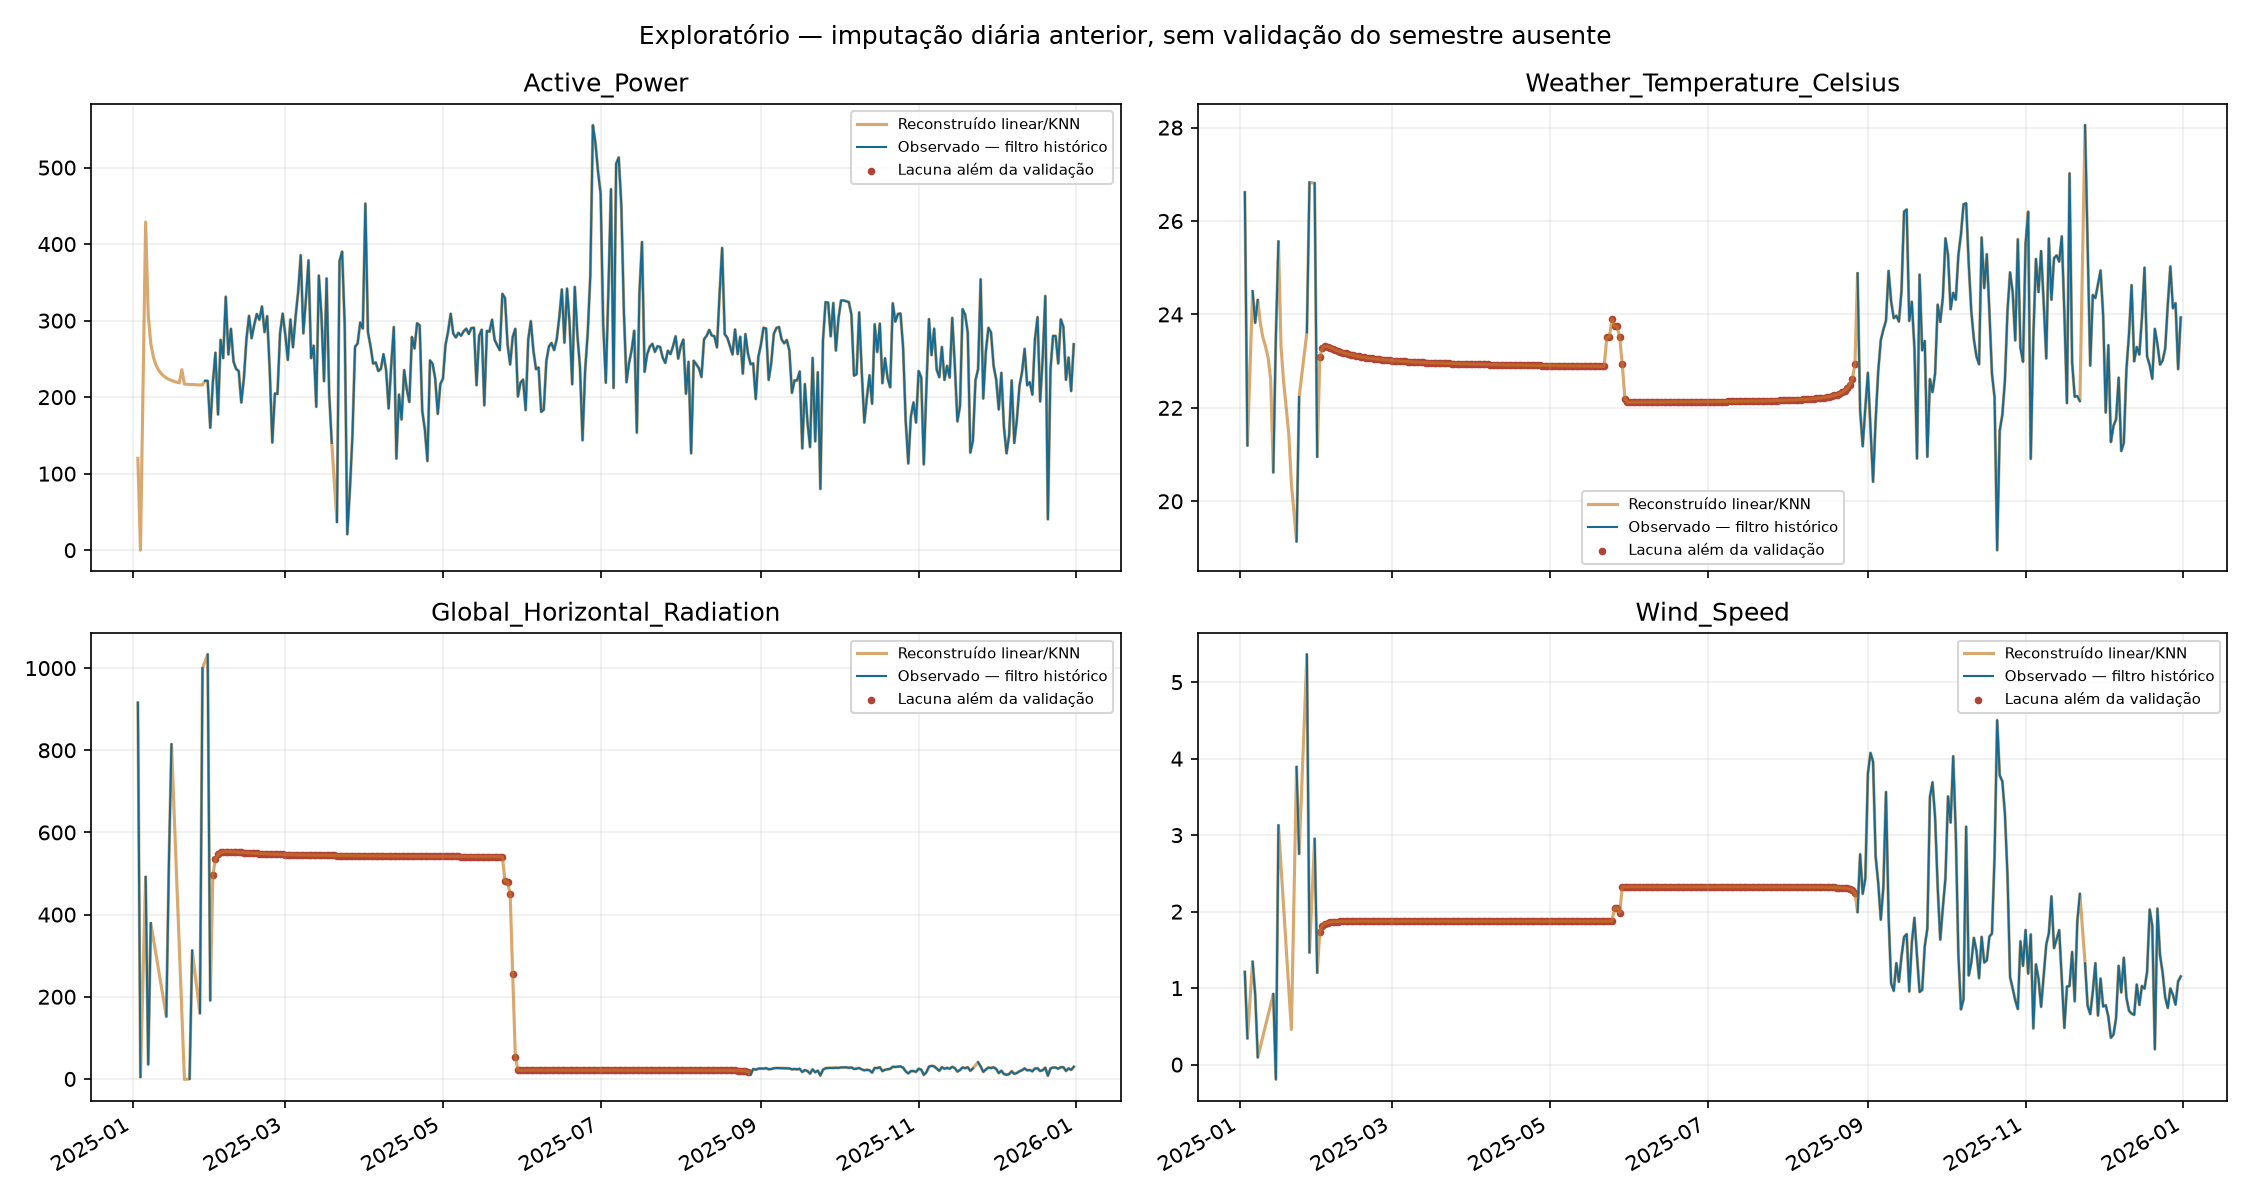

In [3]:
display(Image(filename=str(CAMINHOS.figuras / "diagnostico_imputacao_leopoldo.png")))